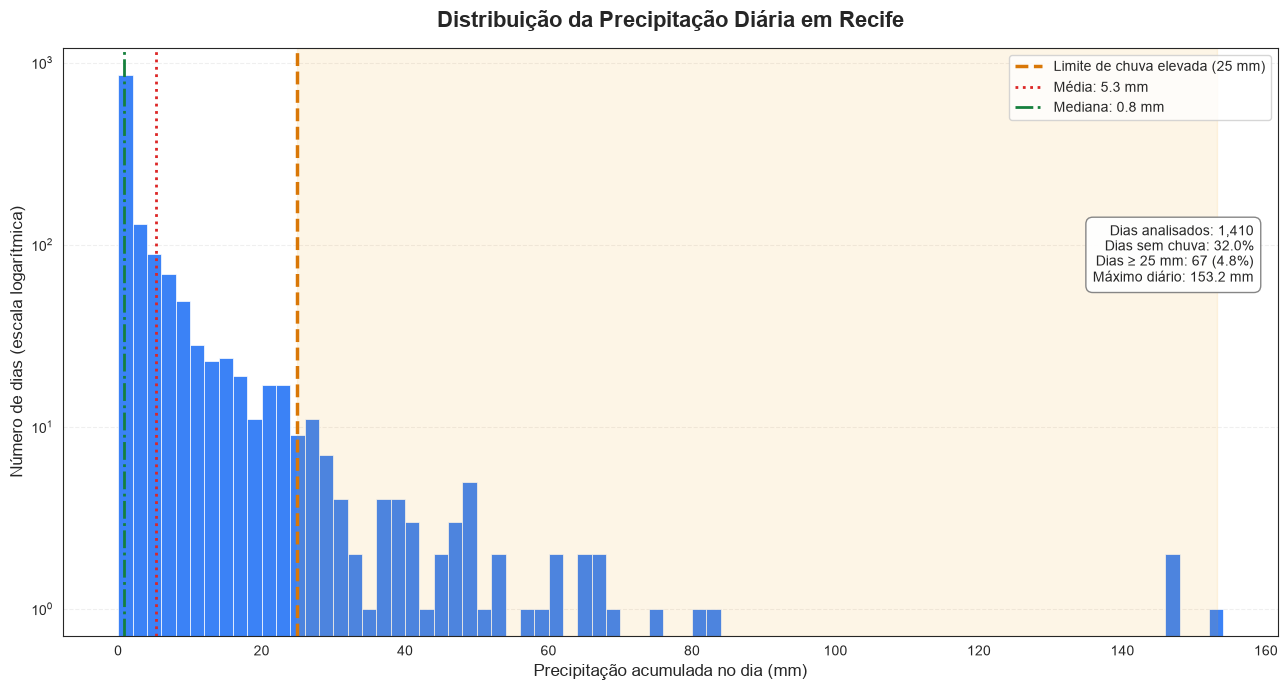

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    r'C:\Users\W2 ASSISTENCIA\Downloads\PSI3\dados\df_recife_datetime.csv'
)

coluna_chuva = 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'

df['datetime'] = pd.to_datetime(df['datetime'])
df[coluna_chuva] = pd.to_numeric(df[coluna_chuva], errors='coerce')
df = df.dropna(subset=['datetime', coluna_chuva])

chuva_diaria = (
    df.set_index('datetime')[coluna_chuva]
    .resample('D')
    .sum()
    .dropna()
)

media = chuva_diaria.mean()
mediana = chuva_diaria.median()
maximo = chuva_diaria.max()
limite = 25

dias_chuva_elevada = (chuva_diaria >= limite).sum()
percentual_elevada = dias_chuva_elevada / len(chuva_diaria) * 100
percentual_seco = (chuva_diaria == 0).mean() * 100


fig, ax = plt.subplots(figsize=(13, 7))

largura_bin = 2
bins = np.arange(
    0,
    np.ceil(chuva_diaria.max() / largura_bin) * largura_bin + largura_bin,
    largura_bin
)

ax.hist(
    chuva_diaria,
    bins=bins,
    color='#3B82F6',
    edgecolor='white',
    linewidth=0.5
)

ax.set_yscale('log')

ax.axvspan(
    limite,
    chuva_diaria.max(),
    color='#F59E0B',
    alpha=0.10
)

ax.axvline(
    limite,
    color='#D97706',
    linestyle='--',
    linewidth=2.5,
    label=f'Limite de chuva elevada ({limite} mm)'
)

ax.axvline(
    media,
    color='#DC2626',
    linestyle=':',
    linewidth=2,
    label=f'Média: {media:.1f} mm'
)

ax.axvline(
    mediana,
    color='#15803D',
    linestyle='-.',
    linewidth=2,
    label=f'Mediana: {mediana:.1f} mm'
)

ax.set_title(
    'Distribuição da Precipitação Diária em Recife',
    fontsize=16,
    weight='bold',
    pad=15
)
ax.set_xlabel('Precipitação acumulada no dia (mm)', fontsize=12)
ax.set_ylabel('Número de dias (escala logarítmica)', fontsize=12)

ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(loc='upper right', frameon=True, fontsize=10)

resumo = (
    f'Dias analisados: {len(chuva_diaria):,}\n'
    f'Dias sem chuva: {percentual_seco:.1f}%\n'
    f'Dias ≥ 25 mm: {dias_chuva_elevada} ({percentual_elevada:.1f}%)\n'
    f'Máximo diário: {maximo:.1f} mm'
)

ax.text(
    0.98, 0.70, resumo,
    transform=ax.transAxes,
    ha='right', va='top',
    fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.95)
)

plt.tight_layout()
plt.show()


### Entendendo a distribuição da chuva dia a dia

Esse gráfico nos ajuda a enxergar o que acontece no dia a dia da cidade. Como a escala está em formato logarítmico, conseguimos ver tanto os dias normais quanto os temporais mais pesados.

* **A maioria dos dias é seca ou com pouca chuva:** A nossa mediana fica bem baixa (em 0,8 mm), o que mostra que na maior parte do tempo a chuva é fraca ou nem existe (cerca de 32% dos dias do histórico não tiveram pingo de chuva).
* **Os dias de chuva forte:** A linha tracejada laranja marca o limite de 25 mm por dia. Apenas uma parcela pequena dos dias (cerca de 4,8%) passa dessa marca.
* **O extremo:** Na ponta direita, o gráfico mostra que já tivemos dias extremos na cidade chegando a mais de 150 mm acumulados em 24 horas.

C:\Users\W2 ASSISTENCIA\AppData\Local\Temp\ipykernel_24380\2080755181.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


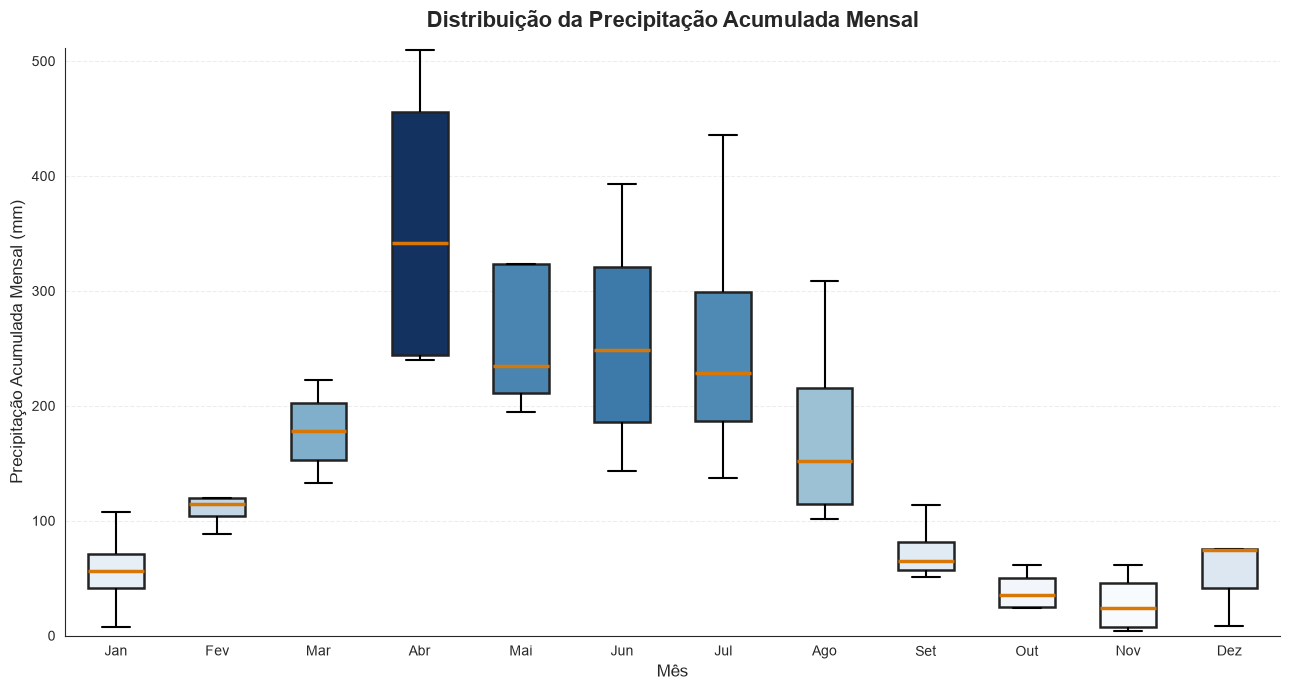

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.colors as mcolors

df = pd.read_csv(
    r'C:\Users\W2 ASSISTENCIA\Downloads\PSI3\dados\df_recife_datetime.csv'
)

coluna_chuva = 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'

df['datetime'] = pd.to_datetime(df['datetime'])
df[coluna_chuva] = pd.to_numeric(df[coluna_chuva], errors='coerce')
df = df.dropna(subset=['datetime', coluna_chuva])

chuva_mensal = (
    df.set_index('datetime')[coluna_chuva]
    .resample('MS')
    .sum()
    .reset_index()
)

chuva_mensal['mes'] = chuva_mensal['datetime'].dt.month

meses = [
    'Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
    'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'
]

chuva_mensal['mes_nome'] = chuva_mensal['mes'].map(
    dict(enumerate(meses, start=1))
)

ordem_medistas = chuva_mensal.groupby('mes_nome')[coluna_chuva].median().reindex(meses)

min_val = ordem_medistas.min()
max_val = ordem_medistas.max()

if max_val - min_val > 0:
    norm = mcolors.Normalize(vmin=min_val, vmax=max_val)
    paleta_cores = {mes: cm.Blues(norm(val)) for mes, val in ordem_medistas.items()}
else:
    paleta_cores = {mes: cm.Blues(0.5) for mes in meses}

sns.set_style('white')

fig, ax = plt.subplots(figsize=(13, 7))

sns.boxplot(
    data=chuva_mensal,
    x='mes_nome',
    y=coluna_chuva,
    order=meses,
    palette=paleta_cores,
    width=0.55,
    linewidth=1.8,
    showfliers=True,
    flierprops={
        'marker': 'o',
        'markersize': 3,
        'markerfacecolor': 'black',
        'markeredgecolor': 'black',
        'alpha': 0.35
    },
    medianprops={
        'color': '#D97706',
        'linewidth': 2.5
    },
    whiskerprops={
        'color': 'black',
        'linewidth': 1.5
    },
    capprops={
        'color': 'black',
        'linewidth': 1.5
    },
    boxprops={
        'linewidth': 1.8
    },
    ax=ax
)

limite_y = chuva_mensal[coluna_chuva].quantile(0.98)
ax.set_ylim(0, limite_y)

ax.set_title(
    'Distribuição da Precipitação Acumulada Mensal',
    fontsize=16,
    weight='bold',
    pad=15
)

ax.set_xlabel('Mês', fontsize=12)
ax.set_ylabel('Precipitação Acumulada Mensal (mm)', fontsize=12)

ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.grid(axis='x', visible=False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Como se comportam as chuvas ao longo dos meses em Recife?

Olhando para esse gráfico de caixas, dá para perceber claramente como o clima de Recife é dividido entre meses mais secos e meses de muita chuva. 

* **O período chove-não-chove:** Fica super visível que os meses do meio do ano — especialmente entre abril e julho — concentram o grosso de toda a chuva do ano. 
* **O pico de abril:** O mês de abril realmente se destaca como o mais intenso, tendo a maior média e podendo registrar acumulados que ultrapassam os 500 mm em anos mais chuvosos.
* **A época seca:** Já na reta final do ano, ali por volta de outubro, novembro e dezembro, as caixas ficam bem miúdas lá embaixo, mostrando que quase não chove nesse período.

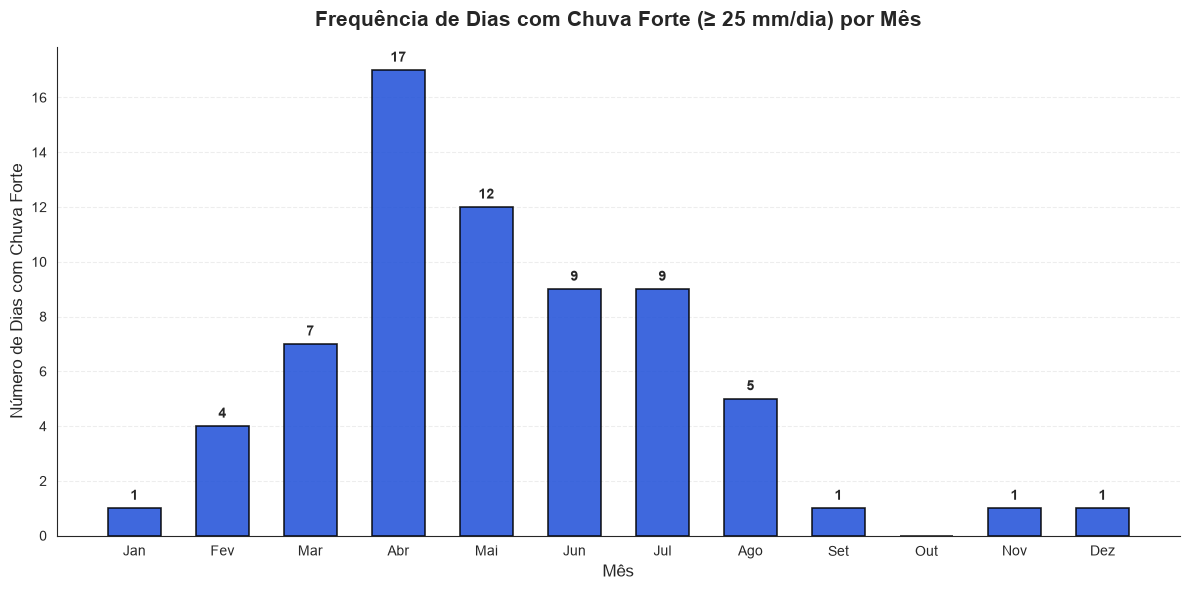

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    r'C:\Users\W2 ASSISTENCIA\Downloads\PSI3\dados\df_recife_datetime.csv'
)

coluna_chuva = 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'

df['datetime'] = pd.to_datetime(df['datetime'])
df[coluna_chuva] = pd.to_numeric(df[coluna_chuva], errors='coerce')
df = df.dropna(subset=['datetime', coluna_chuva])

chuva_diaria = (
    df.set_index('datetime')[coluna_chuva]
    .resample('D')
    .sum()
    .reset_index()
)

chuva_diaria['mes'] = chuva_diaria['datetime'].dt.month

limite_forte = 25
chuva_diaria['chuva_forte'] = chuva_diaria[coluna_chuva] >= limite_forte

frequencia_mes = (
    chuva_diaria.groupby('mes')['chuva_forte']
    .sum()
    .reset_index()
)

meses = [
    'Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
    'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'
]

frequencia_mes['mes_nome'] = frequencia_mes['mes'].map(
    dict(enumerate(meses, start=1))
)

sns.set_style('white')

fig, ax = plt.subplots(figsize=(12, 6))

barras = ax.bar(
    frequencia_mes['mes_nome'],
    frequencia_mes['chuva_forte'],
    color='#1D4ED8',
    edgecolor='black',
    linewidth=1.2,
    width=0.6,
    alpha=0.85
)

for barra in barras:
    altura = barra.get_height()
    if altura > 0:
        ax.annotate(
            f'{int(altura)}',
            xy=(barra.get_x() + barra.get_width() / 2, altura),
            xytext=(0, 4),
            textcoords='offset points',
            ha='center', va='bottom',
            fontsize=10,
            weight='bold'
        )

ax.set_title(
    f'Frequência de Dias com Chuva Forte (≥ {limite_forte} mm/dia) por Mês',
    fontsize=15,
    weight='bold',
    pad=15
)

ax.set_xlabel('Mês', fontsize=12)
ax.set_ylabel('Número de Dias com Chuva Forte', fontsize=12)

ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.grid(axis='x', visible=False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Em quais meses é mais provável pegar uma chuva forte?

Esse gráfico de barras responde diretamente à pergunta: *quando a gente deve se preocupar mais com temporais e chuvas intensas?*

* **A temporada de alertas:** Fica óbvio que o risco de pegar dias de chuva forte (acima de 25 mm) se concentra de março a agosto. 
* **O mês mais pesado:** Abril lidera disparado com 17 registros de dias fortes, seguido de perto por maio, junho e julho. 
* **Calmaria no resto do ano:** De setembro a fevereiro, a barra de dias fortes praticamente some, provando que esses meses são bem mais tranquilos em relação a temporais.
